<a href="https://colab.research.google.com/github/leeknnn/viktoriiashkorubska-41/blob/master/lab_work_17/lab_work_17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Завдання 1: Побудова регресійної моделі ---
Рівняння: витрати ≈ 2.317 + -0.124 * температура
p-value моделі: 1.5285e-03

--- Завдання 2: Коефіцієнт детермінації ---
R² (з linregress): 0.6504
R² (ручний розрахунок за формулою): 0.6504
r² (через коефіцієнт кореляції Пірсона): 0.6504

--- Завдання 3: Графік залишків ---


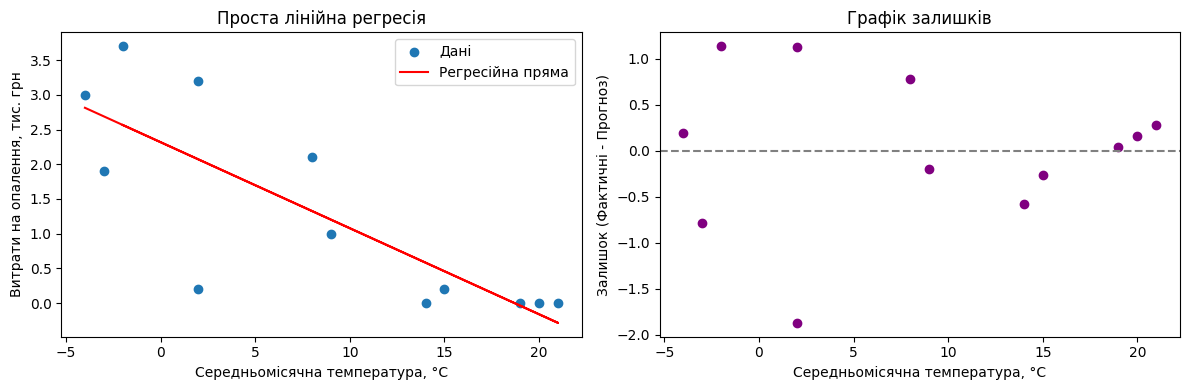


--- Завдання 4: Прогноз і екстраполяція ---
Прогнозовані витрати для температури -10°C: 3.556 тис. грн
Спостережуваний діапазон температур: від -4°C до 21°C


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress, pearsonr

# Варіант 1: Київ
np.random.seed(1)
city = "Київ"
monthly_temp = [-4, -3, 2, 9, 15, 19, 21, 20, 14, 8, 2, -2]
months = ["Січ", "Лют", "Бер", "Кві", "Тра", "Чер",
          "Лип", "Сер", "Вер", "Жов", "Лис", "Гру"]

rows = []
for month, temp in zip(months, monthly_temp):
    heating_days = np.clip(18 - temp + np.random.normal(0, 1.5), 0, 30)
    heating_days = round(heating_days)
    cost = 0.15 * heating_days + np.random.normal(0, 1.0)
    cost = round(max(cost, 0), 1)
    rows.append({
        "місто": city, "місяць": month, "температура": temp,
        "опалювальні_дні": heating_days, "витрати_на_опалення": cost,
    })
climate = pd.DataFrame(rows)

print("--- Завдання 1: Побудова регресійної моделі ---")
X = climate["температура"]
Y = climate["витрати_на_опалення"]

reg_res = linregress(X, Y)
print(f"Рівняння: витрати ≈ {reg_res.intercept:.3f} + {reg_res.slope:.3f} * температура")
print(f"p-value моделі: {reg_res.pvalue:.4e}")

print("\n--- Завдання 2: Коефіцієнт детермінації ---")
r2_from_linreg = reg_res.rvalue ** 2

predicted_vals = reg_res.intercept + reg_res.slope * X
residuals = Y - predicted_vals

ss_residuals = np.sum(residuals ** 2)
ss_total = np.sum((Y - Y.mean()) ** 2)
r2_manual = 1 - (ss_residuals / ss_total)

r_corr, _ = pearsonr(X, Y)
r2_from_corr = r_corr ** 2

print(f"R² (з linregress): {r2_from_linreg:.4f}")
print(f"R² (ручний розрахунок за формулою): {r2_manual:.4f}")
print(f"r² (через коефіцієнт кореляції Пірсона): {r2_from_corr:.4f}")

print("\n--- Завдання 3: Графік залишків ---")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.scatter(X, Y, label="Дані")
ax1.plot(X, predicted_vals, color="red", label="Регресійна пряма")
ax1.set_xlabel("Середньомісячна температура, °C")
ax1.set_ylabel("Витрати на опалення, тис. грн")
ax1.set_title("Проста лінійна регресія")
ax1.legend()

ax2.scatter(X, residuals, color="purple")
ax2.axhline(0, color="gray", linestyle="--")
ax2.set_xlabel("Середньомісячна температура, °C")
ax2.set_ylabel("Залишок (Фактичні - Прогноз)")
ax2.set_title("Графік залишків")

plt.tight_layout()
plt.show()

print("\n--- Завдання 4: Прогноз і екстраполяція ---")
x_new = -10.0
y_pred = reg_res.intercept + reg_res.slope * x_new
print(f"Прогнозовані витрати для температури -10°C: {y_pred:.3f} тис. грн")
print(f"Спостережуваний діапазон температур: від {X.min()}°C до {X.max()}°C")

## Відповіді на контрольні питання

1. **Чому метод найменших квадратів мінімізує саме суму квадратів залишків, а не суму самих залишків чи їхніх модулів?**
   - Піднесення залишків до квадрата дозволяє уникнути взаємного погашення додатних та від'ємних похибок (що неминуче сталося б при сумуванні простих різниць) і водночас надає більшої ваги значним відхиленням. Крім того, квадратична функція є неперервно диференційовною у всіх точках, що робить математичне знаходження мінімуму за допомогою похідних набагато простішим порівняно з модулями.

2. **Що означає коефіцієнт нахилу $b_1$ змістовно і чим він відрізняється від коефіцієнта кореляції $r$?**
   - Нахил $b_1$ вимірює абсолютну швидкість зміни залежної змінної у тих же фізичних одиницях вимірювання (на скільки тис. грн змінюються витрати при зміні температури на 1°C). Натомість коефіцієнт кореляції $r$ є безрозмірною відносною величиною, яка показує лише тісноту та силу лінійного зв'язку незалежно від масштабів вимірювання обох змінних.

3. **Чому високий $R^2$ сам по собі не є достатньою підставою вважати лінійну модель адекватною?**
   - Значення $R^2$ показує лише частку поясненої дисперсії, але воно не здатне виявити нелінійні патерни, наявність неоднорідних підгруп або систематичні зсуви. Графік залишків дозволяє візуально перевірити виконання ключових припущень регресії — зокрема те, чи є залишки випадковим шумом без помітної структури.

4. **Що змінюється в надійності прогнозу, коли значення $x$ виходить за межі спостереженого діапазону даних?**
   - Прогноз за межами спостереженого діапазону (екстраполяція) стає вкрай ризикованим, оскільки модель робить припущення, що лінійний характер зв'язку зберігається і за межами наявних вимірювань, хоча в реальності залежність може змінювати свою форму або насичуватися.